In [12]:
from samana.Data.b2045 import B2045_MIRI
from samana.Model.b2045_model import B2045ModelEPLM3M4Shear
import numpy as np
import matplotlib.pyplot as plt
from lenstronomy.Workflow.fitting_sequence import FittingSequence
import h5py

In [15]:
data = B2045_MIRI()
data.mask_quasar_image_for_reconstruction(True)
model = B2045ModelEPLM3M4Shear(data, shapelets_order=None)
kwargs_lens_macro_init = None

kwargs_model, _, _, _, _, _ = model.setup_kwargs_model(kwargs_lens_macro_init=kwargs_lens_macro_init)
kwargs_params = model.kwargs_params(kwargs_lens_macro_init=kwargs_lens_macro_init)
kwargs_likelihood = model.kwargs_likelihood

fitting_sequence = FittingSequence(data.kwargs_data_joint, kwargs_model, model.kwargs_constraints, 
                                  kwargs_likelihood, kwargs_params)

nthreads = 10
psf_symmetry = 1
fitting_kwargs_list = [
        ['update_settings', {'lens_add_fixed': [[0, ['a1_a','a3_a','a4_a'], [0.0, 0.0, 0.0]]]}],
       # ['update_settings', {'lens_add_fixed': [[0, ['delta_phi_m1', 'delta_phi_m3','delta_phi_m4'], [0.0, 0.0, 0.0]]]}],
        #['update_settings', {'source_add_fixed': [[1, ['n_max'], [0]]]}],
        ['PSO', {'sigma_scale': 1., 'n_particles': 50, 'n_iterations': 100, 'threadCount': nthreads}],
        #['update_settings', {'source_add_fixed': [[1, ['n_max'], [8]]]}],
        #['PSO', {'sigma_scale': 1., 'n_particles': 20, 'n_iterations': 100, 'threadCount': nthreads}],
        #['MCMC', {'n_burn': 50, 'n_run': 25, 'walkerRatio': 4, 'sigma_scale': 0.1, 'threadCount': nthreads}]
                          ]
chain_list = fitting_sequence.fit_sequence(fitting_kwargs_list)
kwargs_result = fitting_sequence.best_fit()

Computing the PSO ...


  0%|                                                                                                                                                                                                                                  | 0/100 [00:00<?, ?it/s]/Users/danielgilman/Code/external/lenstronomy/lenstronomy/LensModel/Solver/solver4point.py:118: RuntimeWarning: The iteration is not making good progress, as measured by the 
 improvement from the last five Jacobian evaluations.
  x = scipy.optimize.fsolve(
  1%|██▏                                                                                                                                                                                                                       | 1/100 [00:00<01:21,  1.22it/s]/Users/danielgilman/Code/external/lenstronomy/lenstronomy/LensModel/Solver/solver4point.py:118: RuntimeWarning: The iteration is not making good progress, as measured by the 
 improvement from the last five Jacobian evaluations.
  x

Max iteration reached! Stopping.
-0.9281322859328907 reduced X^2 of best position
-1056.2145413916296 log likelihood
2276 effective number of data points
[{'theta_E': np.float64(1.7354622330590834), 'gamma': np.float64(1.90248700388011), 'e1': np.float64(0.0927697612054167), 'e2': np.float64(-0.09451653022836917), 'center_x': np.float64(0.38355678020213185), 'center_y': np.float64(-0.12408216881610648), 'a1_a': 0.0, 'delta_phi_m1': np.float64(0.20494067724927822), 'a3_a': 0.0, 'delta_phi_m3': np.float64(-0.26399012314533954), 'a4_a': 0.0, 'delta_phi_m4': np.float64(0.6879822234013141)}, {'gamma1': np.float64(0.007689911846854706), 'gamma2': np.float64(-0.013415716606887295), 'ra_0': 0.0, 'dec_0': 0.0}] lens result
[{'amp': 1, 'R_sersic': np.float64(0.43033811323170895), 'n_sersic': np.float64(7.5640631656670125), 'e1': np.float64(0.11052712049623237), 'e2': np.float64(-0.31978669166192114), 'center_x': np.float64(0.11120614597530304), 'center_y': np.float64(-0.016211474711633294)}] sou

-0.8889153893121288 reduced X^2 of all evaluated imaging data combined (without degrees of freedom subtracted).
reduced chi^2 of data  0 =  0.8889153893121288
(28, ['gamma_lens0', 'delta_phi_m1_lens0', 'delta_phi_m3_lens0', 'delta_phi_m4_lens0', 'gamma1_lens1', 'gamma2_lens1', 'R_sersic_source_light0', 'n_sersic_source_light0', 'e1_source_light0', 'e2_source_light0', 'R_sersic_lens_light0', 'n_sersic_lens_light0', 'e1_lens_light0', 'e2_lens_light0', 'center_x_lens_light0', 'center_y_lens_light0', 'R_sersic_lens_light1', 'n_sersic_lens_light1', 'center_x_lens_light1', 'center_y_lens_light1', 'delta_x_image', 'delta_x_image', 'delta_x_image', 'delta_x_image', 'delta_y_image', 'delta_y_image', 'delta_y_image', 'delta_y_image'])


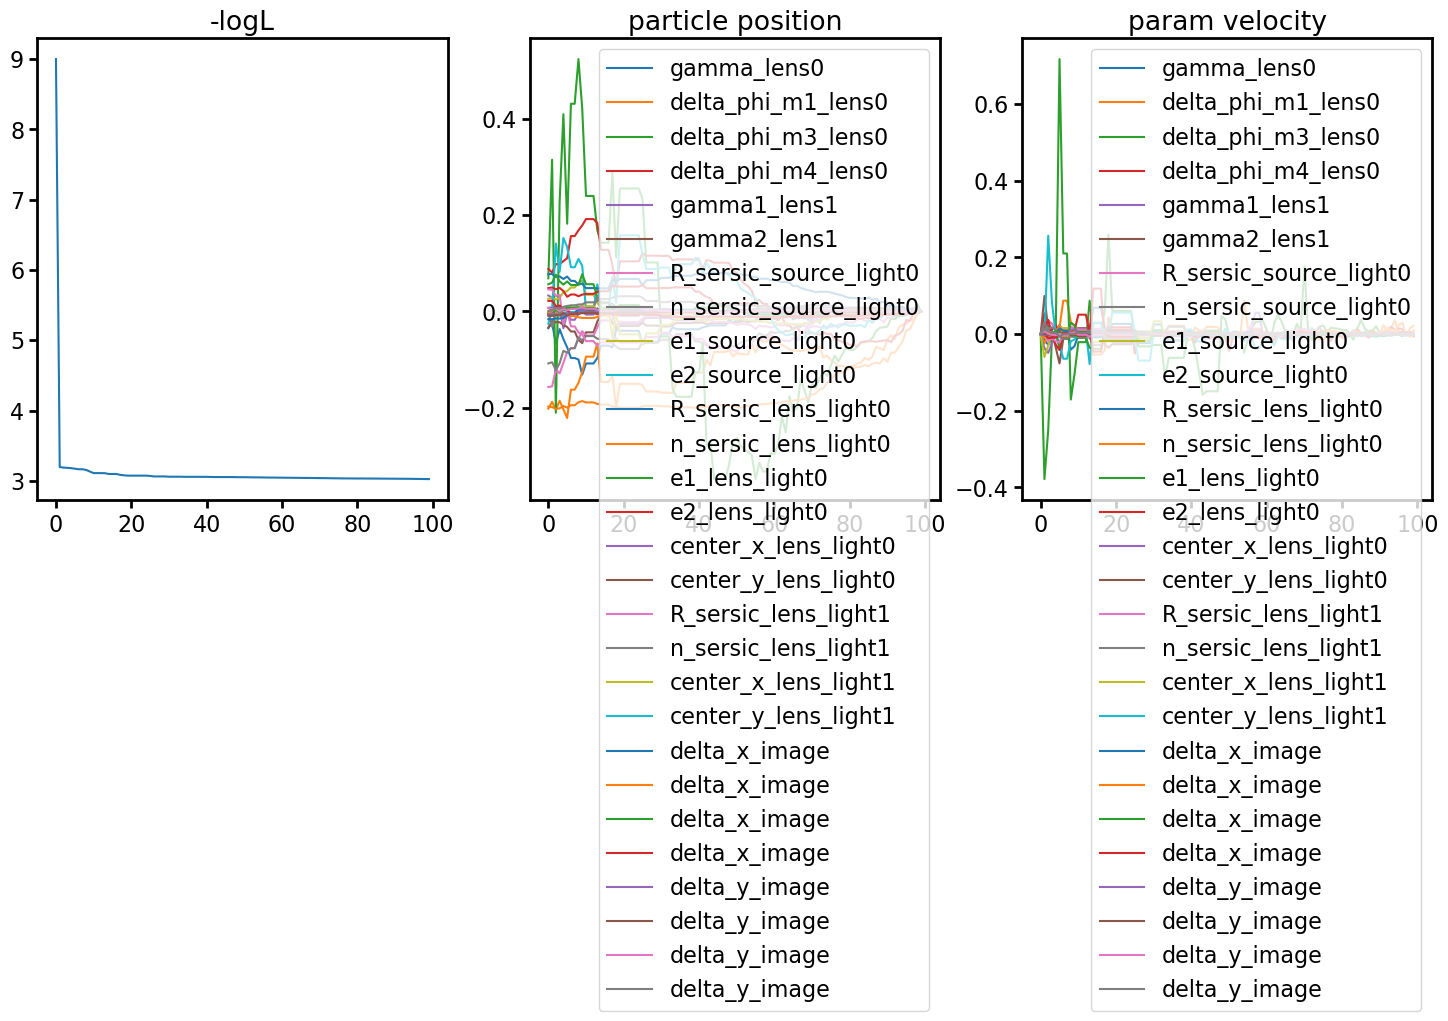

<Figure size 640x480 with 0 Axes>

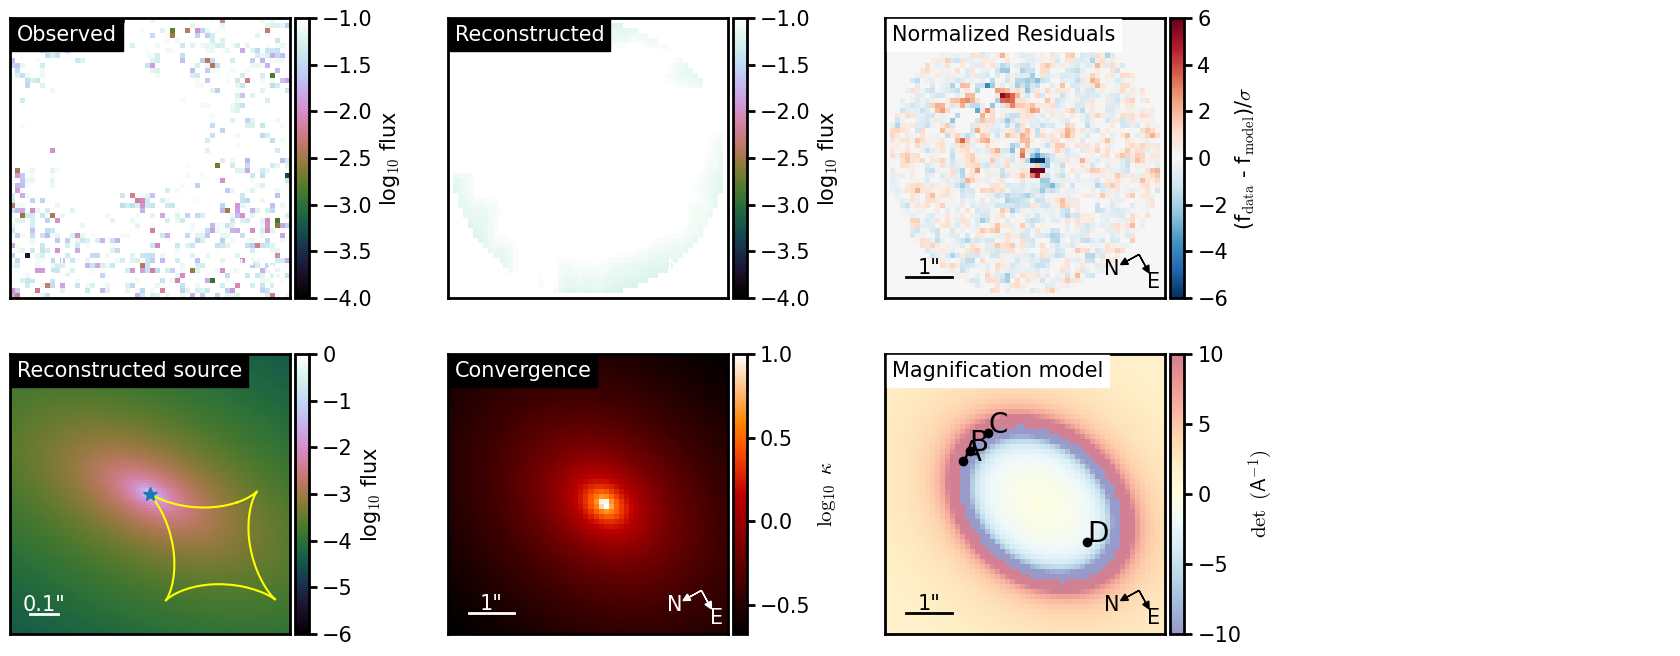

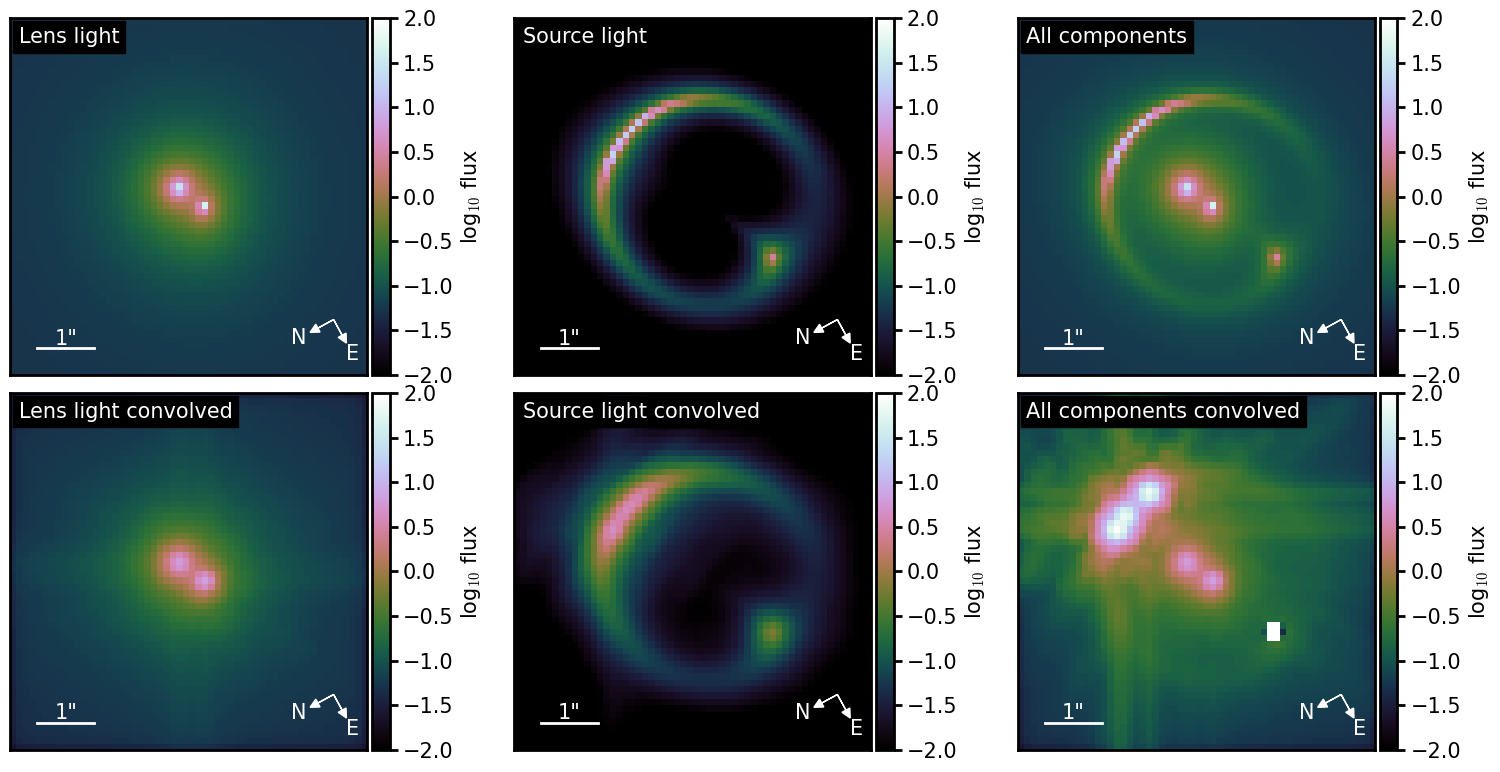

[{'theta_E': np.float64(1.7354622330590834), 'gamma': np.float64(1.90248700388011), 'e1': np.float64(0.0927697612054167), 'e2': np.float64(-0.09451653022836917), 'center_x': np.float64(0.38355678020213185), 'center_y': np.float64(-0.12408216881610648), 'a1_a': 0.0, 'delta_phi_m1': np.float64(0.20494067724927822), 'a3_a': 0.0, 'delta_phi_m3': np.float64(-0.26399012314533954), 'a4_a': 0.0, 'delta_phi_m4': np.float64(0.6879822234013141)}, {'gamma1': np.float64(0.007689911846854706), 'gamma2': np.float64(-0.013415716606887295), 'ra_0': 0.0, 'dec_0': 0.0}]
[{'amp': np.float64(2.0925571100429825), 'R_sersic': np.float64(0.43033811323170895), 'n_sersic': np.float64(7.5640631656670125), 'e1': np.float64(0.11052712049623237), 'e2': np.float64(-0.31978669166192114), 'center_x': np.float64(0.11120614597530304), 'center_y': np.float64(-0.016211474711633294)}]
[{'amp': np.float64(6.070220484874918), 'R_sersic': np.float64(0.7620510199919585), 'n_sersic': np.float64(6.651802920322346), 'e1': np.floa

In [16]:
from lenstronomy.Plots.model_plot import ModelPlot
from lenstronomy.Plots import chain_plot
import matplotlib.pyplot as plt

multi_band_list = data.kwargs_data_joint['multi_band_list']
modelPlot = ModelPlot(multi_band_list, kwargs_model, kwargs_result,
                      image_likelihood_mask_list=[data.likelihood_mask],fast_caustic=True)

param_class = fitting_sequence.param_class
print(param_class.num_param())
#print(chain_list)

for i in range(len(chain_list)):
    chain_plot.plot_chain_list(chain_list, i)

f, axes = plt.subplots(2, 3, figsize=(16, 8), sharex=False, sharey=False)
modelPlot.data_plot(ax=axes[0, 0],  vmin=-4, vmax=-1)
modelPlot.model_plot(ax=axes[0, 1],  vmin=-4, vmax=-1)
modelPlot.normalized_residual_plot(ax=axes[0, 2], vmin=-6, vmax=6)
modelPlot.source_plot(ax=axes[1, 0], delta_pix_source=0.01, num_pix=100, vmin=-6, vmax=0)
modelPlot.convergence_plot(ax=axes[1, 1], vmax=1)
modelPlot.magnification_plot(ax=axes[1, 2])

f, axes = plt.subplots(2, 3, figsize=(16, 8), sharex=False, sharey=False)
modelPlot.decomposition_plot(ax=axes[0, 0], kwargs_title={'text': 'Lens light'}, lens_light_add=True,
                             unconvolved=True, vmin=-2, vmax=2)
modelPlot.decomposition_plot(ax=axes[1, 0], kwargs_title={'text': 'Lens light convolved'}, lens_light_add=True,
                             vmin=-2, vmax=2)
modelPlot.decomposition_plot(ax=axes[0, 1], kwargs_title={'text': 'Source light'}, source_add=True,
                             unconvolved=True,  vmin=-2, vmax=2)
modelPlot.decomposition_plot(ax=axes[1, 1], kwargs_title={'text': 'Source light convolved'}, source_add=True,
                             vmin=-2, vmax=2)
modelPlot.decomposition_plot(ax=axes[0, 2], kwargs_title={'text': 'All components'}, source_add=True,
                             lens_light_add=True,
                             unconvolved=True, vmin=-2, vmax=2)
modelPlot.decomposition_plot(ax=axes[1, 2], kwargs_title={'text': 'All components convolved'}, 
                             lens_light_add=True,
                             source_add=True,
                             point_source_add=True,
                             unconvolved=False, 
                             vmin=-2, vmax=2)
f.tight_layout()
f.subplots_adjust(left=None, bottom=None, right=None, top=None, wspace=0., hspace=0.05)
plt.show()

#print(kwargs_result)
print(kwargs_result['kwargs_lens'])
print(kwargs_result['kwargs_source'])
print(kwargs_result['kwargs_lens_light'])

-1.2523083217521298 reduced X^2 of all evaluated imaging data combined (without degrees of freedom subtracted).
reduced chi^2 of data  0 =  1.2523083217521298


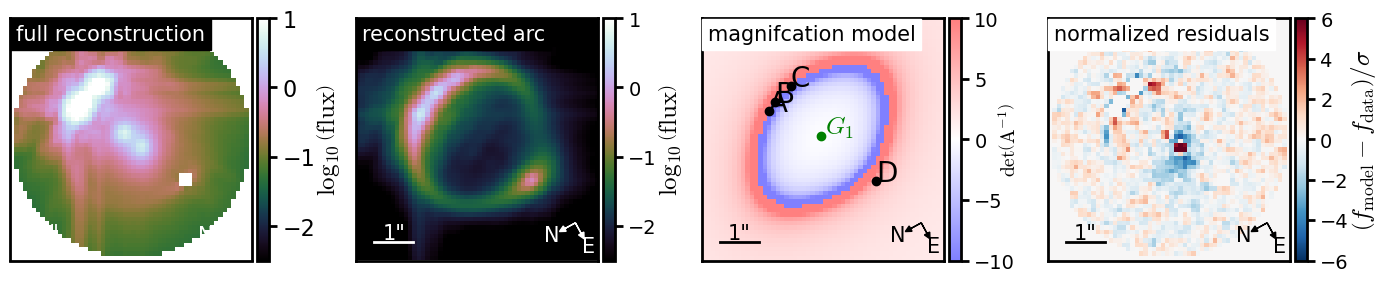

In [5]:
plt.rcParams['axes.linewidth'] = 2.
plt.rcParams['xtick.major.width'] = 2.
plt.rcParams['xtick.major.size'] = 6
plt.rcParams['xtick.minor.width'] = 1.0
plt.rcParams['xtick.minor.size'] = 3.5
plt.rcParams['ytick.major.width'] = 2.0
plt.rcParams['ytick.major.size'] = 6
plt.rcParams['ytick.minor.width'] = 1.0
plt.rcParams['ytick.minor.size'] = 3.5
plt.rcParams.update({'font.size': 16})
plt.rcParams['mathtext.fontset'] = 'cm'

modelPlot = ModelPlot(multi_band_list, kwargs_model, kwargs_result,
                      image_likelihood_mask_list=[data.likelihood_mask],fast_caustic=True)

fig = plt.figure(1)
fig.set_size_inches(14,4.5)

ax1 = plt.subplot(141)
modelPlot._arrow_size = 0
v_min = -2.5
v_max = v_min + 3.5
modelPlot.model_plot(ax=ax1,
                    vmin=v_min,vmax=v_max, kwargs_title={'text': 'full reconstruction'},font_size=16)
im = ax1.images
cb = im[-1].colorbar 
cb.set_label(r'$\log_{10}\left(\rm{flux}\right)$',labelpad=0,fontsize=18)


ax2 = plt.subplot(142)
modelPlot._arrow_size = 0
modelPlot.decomposition_plot(ax=ax2, kwargs_title={'text': 'reconstructed arc'}, unconvolved=False, 
                             source_add=True, vmin=v_min, vmax=v_max,
                             font_size=14)
im = ax2.images
cb = im[-1].colorbar 
#cb.set_ticklabels(ticks,fontsize=16)
cb.set_label(r'$\log_{10}\left(\rm{flux}\right)$',labelpad=0,fontsize=18)

ax3 = plt.subplot(143)
modelPlot._arrow_size = 0
v_min = -3
v_max = v_min + 3.
modelPlot.magnification_plot(ax=ax3, cmap='bwr', kwargs_title={'text': 'magnifcation model'}, font_size=14)
im = ax3.images
cb = im[-1].colorbar 
cb.set_label(r'$\rm{det}\left(A^{-1}\right)$',labelpad=-12)

satx = kwargs_result['kwargs_lens'][0]['center_x']
saty = kwargs_result['kwargs_lens'][0]['center_y']
xplot, yplot = data.coordinate_system.map_coord2pix(satx, saty)
pixel_width = data.coordinate_system.pixel_width
origin = [0,0]
x_ = xplot * pixel_width + origin[0]
y_ = yplot * pixel_width + origin[1]
ax3.plot(x_, y_, ".", color='g',markersize=12,alpha=1.)
ax3.text(x_+0.08, y_+0.05, r'$G_1$', fontsize=18, color='g')

# pixel_width = data.coordinate_system.pixel_width
# origin = [0,0]
# x_ = xplot * pixel_width + origin[0]
# y_ = yplot * pixel_width + origin[1]
# ax3.plot(x_, y_, ".", color='g',markersize=16,alpha=1.)
# ax3.text(x_-0.6, y_-0.75, r'$G_2$', fontsize=16, color='g')


ax4 = plt.subplot(144)
modelPlot._arrow_size = 0
modelPlot.normalized_residual_plot(ax=ax4,
                    vmin=-6, vmax=6, cmap='RdBu_r',font_size=14, kwargs_title={'text': 'normalized residuals'})
im = ax4.images
cb = im[-1].colorbar 
cb.set_label(r'$\left(f_{\rm{model}}-f_{\rm{data}}\right)/\sigma$',labelpad=0,fontsize=18)

plt.subplots_adjust(wspace=-0.43, hspace=0.1)
plt.tight_layout()

plt.savefig('./b2045bmodel_miri.pdf',bbox_inches='tight')